##🎬 Movie Review Sentiment Analysis

#Introduction

Sentiment Analysis is a Natural Language Processing (NLP) technique used to identify and classify the emotional tone of text. In this project, sentiment analysis is applied to movie reviews to determine whether a review expresses a **Positive** or **Negative** sentiment.

The project uses a movie review dataset containing thousands of reviews. The text data is first explored and preprocessed to remove unnecessary elements and prepare it for machine learning.

TF-IDF (Term Frequency-Inverse Document Frequency) is then used to convert the textual reviews into numerical features. A **Logistic Regression** machine learning model is trained using these features to classify reviews into positive or negative categories.

The model is evaluated using **Accuracy, F1-Score, Precision, Recall, Classification Report, and Confusion Matrix**. A sentiment prediction system is also included to allow new movie reviews to be classified by the trained model.

#Objectives

- Analyze the movie review dataset.
- Perform text preprocessing and cleaning.
- Convert text into numerical features using TF-IDF.
- Train a Logistic Regression sentiment classification model.
- Evaluate the model using appropriate performance metrics.
- Predict the sentiment of new movie reviews.

#Technologies Used

- Python
- Google Colab
- Pandas
- NumPy
- NLTK
- Scikit-learn
- Matplotlib
- Seaborn

1. Mount Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


2. Imports + NLTK setup

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

stop_words = set(stopwords.words('english'))

print("Imports and NLTK setup completed!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Imports and NLTK setup completed!


3. Load dataset

In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/Data Science Analytics Internship/Datasets/IMDB_Dataset_CLEANED.csv"

df = pd.read_csv(
    file_path,
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (49396, 2)
Columns: ['review', 'sentiment']


In [ ]:
# List the contents of the directory to verify the file path
!ls "/content/drive/MyDrive/Data Science Analytics Internship/Datasets/"

IMDB_Dataset_CLEANED.csv  processed_reviews.csv  processed_reviews.csv.gsheet


4. Basic dataset checks

In [ ]:
print("First 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

First 5 rows:


,review,sentiment
0,"$25,000 Pyramid Clues: Deep Blue Sea. Tremors....",negative
1,0.5/10. This movie has absolutely nothing good...,negative
2,"0*'s Christian Slater, Tara Reid, Stephen Dorf...",negative
3,"102 Dalmatians (2000, Dir. Kevin Lima) <br /><...",negative
4,102 DALMATIANS [Walt Disney]: I wasn't a fan o...,negative



Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 0

Sentiment distribution:
sentiment
negative    24698
positive    24698
Name: count, dtype: int64


In [ ]:
print(df.shape)
print(df.columns.tolist())

(49396, 2)
['review', 'sentiment']


5. EDA

In [ ]:
# Check dataset information
print("Dataset Information:")
print(df.info())

print("\nSentiment Counts:")
print(df["sentiment"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49396 entries, 0 to 49395
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     49396 non-null  object
 1   sentiment  49396 non-null  object
dtypes: object(2)
memory usage: 771.9+ KB
None

Sentiment Counts:
sentiment
negative    24698
positive    24698
Name: count, dtype: int64


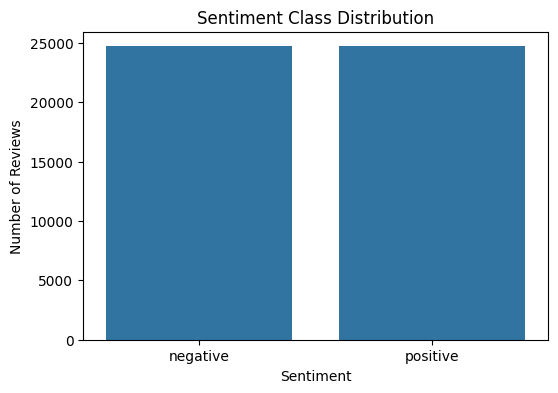

In [ ]:
# Sentiment distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

6. Review Length Analysis

In [ ]:
# Calculate review length
df["review_length"] = df["review"].astype(str).apply(len)

print("Average review length:",
      round(df["review_length"].mean(), 2))

Average review length: 1310.54


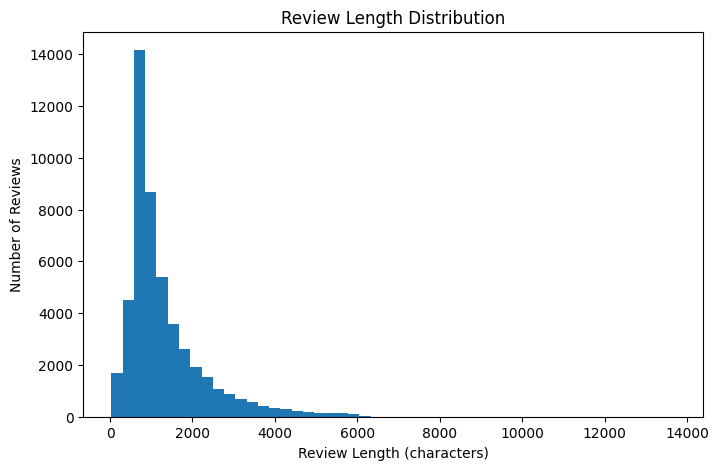

In [ ]:
# Review length distribution
plt.figure(figsize=(8, 5))

plt.hist(df["review_length"], bins=50)

plt.title("Review Length Distribution")
plt.xlabel("Review Length (characters)")
plt.ylabel("Number of Reviews")

plt.show()

7. Preprocessing

In [ ]:
import nltk

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))

print("NLTK setup completed!")

NLTK setup completed!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
def preprocess_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize
    words = word_tokenize(text)

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

print("Preprocessing function created!")

Preprocessing function created!


In [ ]:
print("Starting preprocessing...")

df["cleaned_review"] = df["review"].apply(preprocess_text)

print("Preprocessing completed!")
print(df[["review", "cleaned_review", "sentiment"]].head())

Starting preprocessing...
Preprocessing completed!
                                              review  \
0  $25,000 Pyramid Clues: Deep Blue Sea. Tremors....   
1  0.5/10. This movie has absolutely nothing good...   
2  0*'s Christian Slater, Tara Reid, Stephen Dorf...   
3  102 Dalmatians (2000, Dir. Kevin Lima) <br /><...   
4  102 DALMATIANS [Walt Disney]: I wasn't a fan o...   

                                      cleaned_review sentiment  
0  pyramid clues deep blue sea tremors slither ei...  negative  
1  movie absolutely nothing good acting among wor...  negative  
2  christian slater tara reid stephen dorff frank...  negative  
3  dalmatians dir kevin lima believed cured cruel...  negative  
4  dalmatians walt disney fan previous installmen...  negative  


In [ ]:
processed_path = "/content/drive/MyDrive/Data Science Analytics Internship/Datasets/processed_reviews.csv"

df.to_csv(processed_path, index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


8. Review Analysis

Review Count by Sentiment:
sentiment
negative    24698
positive    24698
Name: count, dtype: int64

Average Review Length by Sentiment:
sentiment
negative    1294.739615
positive    1326.345048
Name: review_length, dtype: float64


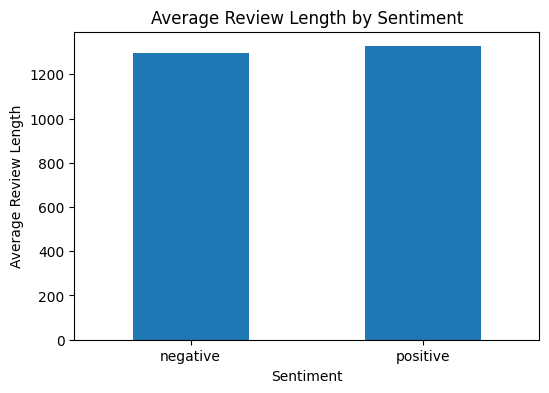

In [ ]:
# ==========================================
# REVIEW ANALYSIS
# ==========================================

# Number of positive and negative reviews
print("Review Count by Sentiment:")
print(df["sentiment"].value_counts())

# Average review length by sentiment
avg_length = df.groupby("sentiment")["review_length"].mean()

print("\nAverage Review Length by Sentiment:")
print(avg_length)

# Plot average review length
plt.figure(figsize=(6, 4))

avg_length.plot(kind="bar")

plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Review Length")

plt.xticks(rotation=0)
plt.show()

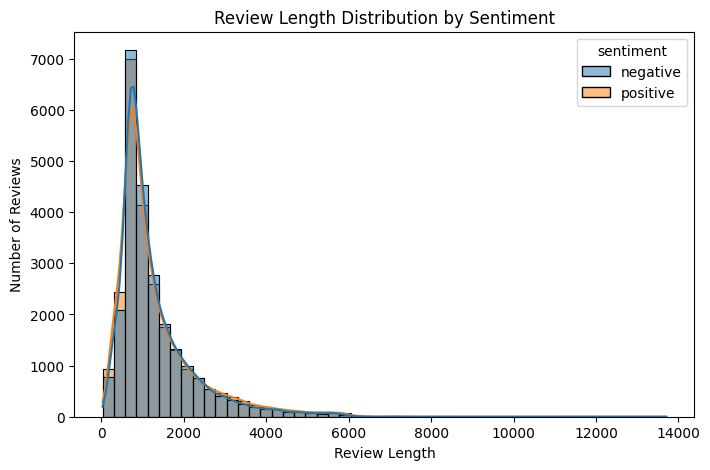

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    kde=True
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")

plt.show()

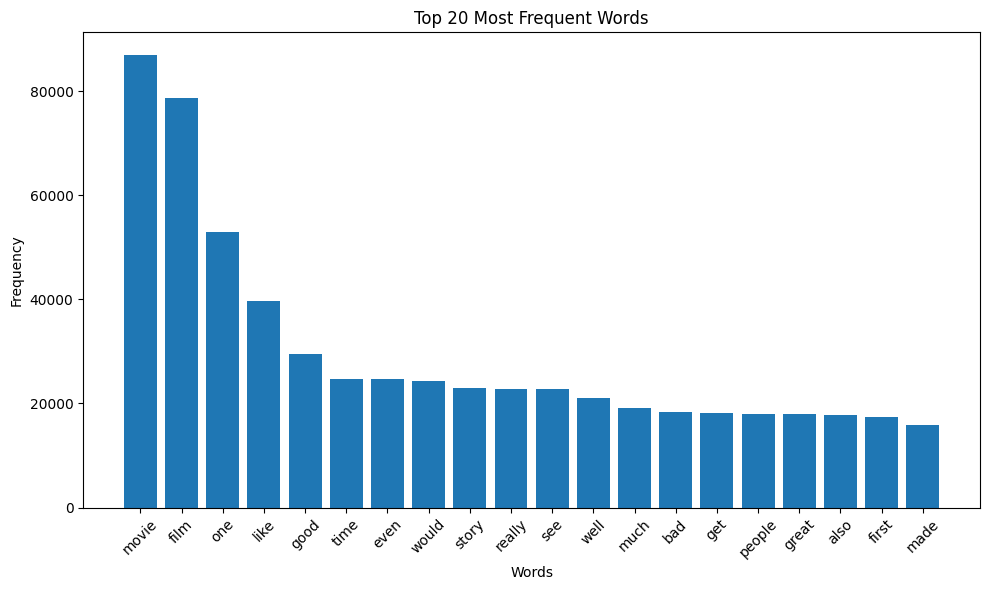

In [ ]:
from collections import Counter

# Combine cleaned reviews
all_words = " ".join(df["cleaned_review"].fillna(""))

# Count words
word_counts = Counter(all_words.split())

# Get top 20 words
top_words = word_counts.most_common(20)

words = [word for word, count in top_words]
counts = [count for word, count in top_words]

plt.figure(figsize=(10, 6))

plt.bar(words, counts)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

9. TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Convert cleaned reviews into numerical features
X = tfidf.fit_transform(df["cleaned_review"].fillna(""))

# Target variable
y = df["sentiment"]

print("TF-IDF completed successfully!")
print("TF-IDF Shape:", X.shape)
print("Labels Shape:", y.shape)

TF-IDF completed successfully!
TF-IDF Shape: (49396, 5000)
Labels Shape: (49396,)


10. Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train-Test Split completed!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Train-Test Split completed!
X_train shape: (39516, 5000)
X_test shape: (9880, 5000)
y_train shape: (39516,)
y_test shape: (9880,)


11. ML Model Training

In [ ]:
from sklearn.linear_model import LogisticRegression

print("Training Logistic Regression model...")

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Training Logistic Regression model...
Model training completed successfully!


12. Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Make predictions
y_pred = model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate F1-score
f1 = f1_score(y_test, y_pred, pos_label="positive")

print("Model Evaluation")
print("-----------------------------")
print("Accuracy:", round(accuracy, 4))
print("F1-Score:", round(f1, 4))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Evaluation
-----------------------------
Accuracy: 0.8908
F1-Score: 0.8922

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      4940
    positive       0.88      0.90      0.89      4940

    accuracy                           0.89      9880
   macro avg       0.89      0.89      0.89      9880
weighted avg       0.89      0.89      0.89      9880



13. Confusion Matrix

Confusion Matrix:
[[4334  606]
 [ 473 4467]]


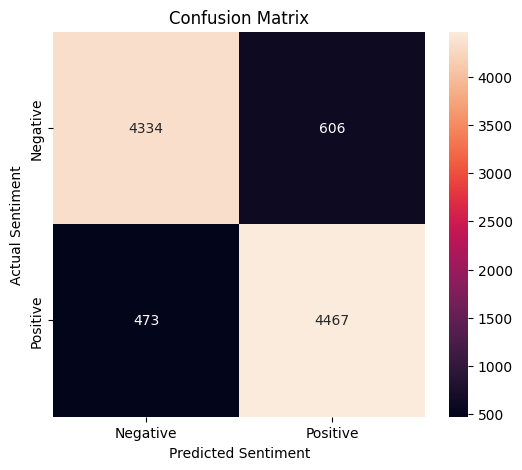

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "positive"]
)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
import joblib

# Save trained model
model_path = "/content/drive/MyDrive/Data Science Analytics Internship/sentiment_model.pkl"
joblib.dump(model, model_path)

# Save TF-IDF vectorizer
tfidf_path = "/content/drive/MyDrive/Data Science Analytics Internship/tfidf_vectorizer.pkl"
joblib.dump(tfidf, tfidf_path)

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


14. Sentiment Prediction

In [ ]:
# ==========================================
# SENTIMENT PREDICTION SYSTEM
# SINGLE + MULTIPLE REVIEWS
# ==========================================

def predict_sentiment(review):
    # Preprocess review
    processed_review = preprocess_text(review)

    # Convert to TF-IDF
    review_tfidf = tfidf.transform([processed_review])

    # Predict sentiment
    prediction = model.predict(review_tfidf)[0]

    return prediction


# Main menu
while True:

    print("\n======================================")
    print("       SENTIMENT PREDICTION SYSTEM")
    print("======================================")
    print("1. Single Review")
    print("2. Multiple Reviews")
    print("3. Exit")
    print("======================================")

    choice = input("Enter your choice (1/2/3): ").strip()

    # -----------------------------
    # SINGLE REVIEW
    # -----------------------------
    if choice == "1":

        review = input("\nEnter your movie review: ").strip()

        if review:
            prediction = predict_sentiment(review)

            print("\n--------------------------------------")
            print("Review:", review)
            print("Predicted Sentiment:", prediction)
            print("--------------------------------------")
        else:
            print("Please enter a review.")

    # -----------------------------
    # MULTIPLE REVIEWS
    # -----------------------------
    elif choice == "2":

        try:
            number = int(
                input("\nHow many reviews do you want to analyze? ")
            )

            if number <= 0:
                print("Please enter a number greater than 0.")
                continue

            print("\nEnter your reviews:")

            for i in range(number):

                review = input(f"\nReview {i + 1}: ").strip()

                if review:
                    prediction = predict_sentiment(review)

                    print("Predicted Sentiment:", prediction)
                else:
                    print("Empty review skipped.")

        except ValueError:
            print("Please enter a valid number.")

    # -----------------------------
    # EXIT
    # -----------------------------
    elif choice == "3":

        print("\nSentiment Prediction System closed.")
        break

    else:

        print("\nInvalid choice. Please enter 1, 2, or 3.")


       SENTIMENT PREDICTION SYSTEM
1. Single Review
2. Multiple Reviews
3. Exit
Enter your choice (1/2/3): 1

Enter your movie review: good

--------------------------------------
Review: good
Predicted Sentiment: positive
--------------------------------------

       SENTIMENT PREDICTION SYSTEM
1. Single Review
2. Multiple Reviews
3. Exit
Enter your choice (1/2/3): 3

Sentiment Prediction System closed.


15. Conclusion

This project developed a machine learning-based Sentiment Analysis system for movie reviews.

The IMDb movie review dataset was explored and preprocessed by converting text to lowercase, removing HTML tags, special characters, numbers, extra spaces, and stopwords.

TF-IDF (Term Frequency-Inverse Document Frequency) was used to convert the cleaned reviews into numerical features. Unigrams and bigrams were used with a maximum of 5,000 features.

The dataset was divided into training and testing sets using an 80:20 split. Logistic Regression was then trained to classify movie reviews as positive or negative.

The model was evaluated using Accuracy, F1-score, Precision, Recall, Classification Report, and a Confusion Matrix.

A sentiment prediction system was also developed that allows users to enter either a single movie review or multiple reviews and receive the predicted sentiment.

Overall, the project demonstrates how Natural Language Processing and Machine Learning can be used to automatically analyze and classify the sentiment of movie reviews.